# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

## ReadMe:
This project is heavily focused on Basketball and thus will use a lot of Basketball terminology one should be familiar with in order to understand some of the motives and methodologies. As such, I've provided a short glossary on the basic terms that I hope will aid in viewing my project:

FGM (Field Goal Made):
 Whether a shot goes in or not, in terms of this project it's a member set of (0,1).

Expected Points (EP):
 The estimated value of a shot, calculated as:
EP = P(make) * shot value. This is further elaborated on later in the project.
where shot value is 2 or 3 points depending on location.

Paint Shot:
 A shot taken near the basket inside the rectangular painted area under the rim, these are usually high percentage attempts as they are easier to score.

Mid-Range Shot:
 A shot taken outside the paint but inside the three-point line, approximately between 10 and 22 feet from the basket, these are still 2 points but harder than the previous shot.

Three-Point Shot (3-Pointer):
 A shot attempted from beyond the three-point line, worth three points instead of two.

Shot Clock:
 A countdown timer that limits how long one team can have the ball before attempting a shot, if the timer runs out, the other team gains possession of the ball.

Step-Back:
 An offensive move where the shooter moves backward before shooting, creating additional distance from the defender. This is a hard shot but a step-back can change the shot from a mid-range to a three-point shot.

Drive:
 An attacking move where a player dribbles toward the basket to improve scoring position (this may mean getting closer to a defender).

Close Defender Distance (CLOSE_DEF_DIST):
 The distance, in feet, between the shooter and the nearest defender at the moment of the shot, the closer the defender, the harder the shot (usually).

Late-Clock Bailout Shot:
 A difficult shot taken with very little time remaining on the shot clock, often because the offensive possession failed to generate a better opportunity.
A bad 'forced' shot is also called a Heave (ie the player just threw up a shot and hoped it went in).


---

## Recap from H1: what you committed to

**Problem (from H1):** When watching game footage, basketball coaches can become results-driven and praise a contested mid-range jumper just because it went in, while criticising a wide-open three-pointer that happened to miss. It takes hours to manually check 80 – 100 shots. This project combines an automatic shot quality and tactical relocation system for a coach with a separation of the actual shot outcome from the quality of the shot decision, and proposes whether to shoot the shot immediately, or take a few dribbles to get into a better location.

**Technique(s) (from H1):** The hybrid algorithm was a combination of FIT1061 linear evaluation, local search (steepest-ascent and random-restart hill climbing) and gradient-based learning, which was further extended with penalised logistic regression from my concurrent data modelling unit.

**Data (from H1):** Using the 10,000-shot sample of the Kaggle NBA Shot Logs dataset, five base measurements of the shots were used: shot distance, defender distance, shot clock, number of dribbles, and touch time, along with point values (PTS_TYPE: 2 or 3 points) and binary shot outcomes (FGM: 1 = made, 0 = missed; mapped to +1 / -1 for P8b/D3 comparisons).

**What makes this HD-level (from H1):** Rather than just running basic gradient descent on a new dataset, this project implements three custom extensions in NumPy: first, non-linear polynomial and interaction feature expansion; second, regularised logistic regression minimising logarithmic loss with an L2 ridge penalty trained via mini-batch gradient descent with momentum and random-restart warm-starts; and third, a hill-climbing tactical shot relocator that climbs the Expected Points surface.

**Pivot since H1 (if any):** Based on H1 feedback, two targeted upgrades were made:
1. Separating Shot Outcome from Shot Quality: In H1, the target label was simply made (+1) vs. missed (-1), which risked equating a lucky make with a good decision. In H2, the model trains on binary shot outcomes (FGM = 0, 1) using Logistic Regression to predict continuous Make Probability p = P(Make|x), and multiplies p by the shot's point value (2 or 3) to calculate **Expected Points (EP)**. A wide-open 3-pointer with p = 0.36 yields EP = 1.08 (graded as a High-Quality Shot even if it misses), directly resolving the framing gap.
2. Algorithmic Extension Beyond P8b/D3: Upgraded the linear squared-error loop from D3 into a full Regularised Logistic Regression + Mini-Batch Momentum engine paired with C1/P4 Hill Climbing.

In [1]:
# --- SETUP ---
import numpy as np
import matplotlib.pyplot as plt
import csv
import os

SEED = 42
np.random.seed(SEED)

# using csv and os from standard python so we dont need pandas

print("Setup OK.")

Setup OK.


### Data

In [2]:
# --- DATA ---

# --- YOUR CODE HERE ---

# fallback function from H1.3 just in case the csv file doesnt load
# not really strictly necessary in hindsight but I mentioned this in H1 so might as well
def generate_synthetic_shots(n_samples):
    raw_rows = []
    pts_list = []
    y_01_list = []
    y_pm_list = []
    
    for i in range(n_samples):
        shot_dist = np.random.uniform(1.0, 28.0)
        close_def_dist = np.random.uniform(0.5, 12.0)
        shot_clock = np.random.uniform(1.0, 24.0)
        dribbles = float(np.random.randint(0, 12))
        touch_time = dribbles * 0.8 + np.random.uniform(0.5, 2.0)
        
        # basic formula to simulate make probability
        true_score = 0.6 - 0.08 * shot_dist + 0.18 * close_def_dist + 0.02 * shot_clock - 0.05 * dribbles
        true_prob = 1.0 / (1.0 + np.exp(-true_score))
        
        if np.random.uniform(0.0, 1.0) < true_prob:
            fgm = 1.0
            y_pm = 1.0
        else:
            fgm = 0.0
            y_pm = -1.0
            
        if shot_dist >= 22.0:
            pts_type = 3.0
        else:
            pts_type = 2.0
            
        raw_rows.append([shot_dist, close_def_dist, shot_clock, dribbles, touch_time])
        pts_list.append(pts_type)
        y_01_list.append(fgm)
        y_pm_list.append(y_pm)
        
    return np.array(raw_rows), np.array(y_01_list), np.array(y_pm_list), np.array(pts_list)


# 1) load 10,000 shots from shot_logs.csv and clean up broken rows (risk 1)
MAX_ROWS = 10000
MEDIAN_SHOT_CLOCK = 12.2 # median value to fill in when shot clock is turned off at end of quarter

X_raw_list = []
y_01_list = []   # 1 for make, 0 for miss (for logistic regression)
y_pm_list = []   # +1 for make, -1 for miss (for P8b and D3 funciones)
pts_type_list = []

missing_clock_count = 0
negative_touch_count = 0

if os.path.exists("shot_logs.csv"):
    print("Loading NBA Shot Logs from: shot_logs.csv")
    with open("shot_logs.csv", mode="r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if len(X_raw_list) >= MAX_ROWS:
                break
                
            # skip sensor glitch rows where touch time is negative
            touch_time_str = row["TOUCH_TIME"]
            if touch_time_str == "":
                continue
            touch_time = float(touch_time_str)
            if touch_time < 0.0:
                negative_touch_count = negative_touch_count + 1
                continue
                
            # if shot clock is blank, replace it with the median 12.2s
            shot_clock_str = row["SHOT_CLOCK"]
            if shot_clock_str == "":
                shot_clock = MEDIAN_SHOT_CLOCK
                missing_clock_count = missing_clock_count + 1
            else:
                shot_clock = float(shot_clock_str)
                
            shot_dist = float(row["SHOT_DIST"])
            close_def_dist = float(row["CLOSE_DEF_DIST"])
            dribbles = float(row["DRIBBLES"])
            fgm = float(row["FGM"])
            pts_type = float(row["PTS_TYPE"])
            
            X_raw_list.append([shot_dist, close_def_dist, shot_clock, dribbles, touch_time])
            pts_type_list.append(pts_type)
            
            if fgm == 1.0:
                y_01_list.append(1.0)
                y_pm_list.append(1.0)
            else:
                y_01_list.append(0.0)
                y_pm_list.append(-1.0)
                
    X_raw = np.array(X_raw_list)
    y_01 = np.array(y_01_list)
    y_pm = np.array(y_pm_list)
    pts_type = np.array(pts_type_list)
else:
    print("csv not found, running fallback generator...")
    X_raw, y_01, y_pm, pts_type = generate_synthetic_shots(MAX_ROWS)


# 2) add the 3 new non-linear features to get 8 features total
def expand_basketball_features(X_base):
    n_rows = len(X_base)
    X_expanded = np.zeros((n_rows, 8))
    # np.zero is more efficient than doing (for reference for all new numpy functions used: https://numpy.org/doc/stable/user/absolute_beginners.html):
    # X_expanded = []
    # for row in X:
    #     expanded_row = [0] * 8
    #     X_expanded.append(expanded_row)

    X_expanded = np.array(X_expanded)
    
    for i in range(n_rows):
        dist = X_base[i, 0]
        def_dist = X_base[i, 1]
        clock = X_base[i, 2]
        drib = X_base[i, 3]
        touch = X_base[i, 4]
        
        # feature 6: distance squared (for non-linear drop off on deep shots)
        dist_sq = dist * dist
        
        # feature 7: interaction between shot distance and defender distance
        contest_interaction = dist * def_dist
        
        # feature 8: dribble pace (dribbles per second of touch time, +1 so we dont divide by 0)
        dribble_pace = drib / (touch + 1.0)
        
        X_expanded[i, 0] = dist
        X_expanded[i, 1] = def_dist
        X_expanded[i, 2] = clock
        X_expanded[i, 3] = drib
        X_expanded[i, 4] = touch
        X_expanded[i, 5] = dist_sq
        X_expanded[i, 6] = contest_interaction
        X_expanded[i, 7] = dribble_pace
        
    return X_expanded

feature_names_5d = ["SHOT_DIST", "CLOSE_DEF_DIST", "SHOT_CLOCK", "DRIBBLES", "TOUCH_TIME"]
feature_names_8d = [
    "SHOT_DIST", "CLOSE_DEF_DIST", "SHOT_CLOCK", "DRIBBLES", "TOUCH_TIME",
    "DIST_SQUARED", "DIST_x_DEF_DIST", "DRIBBLE_PACE"
]

X_exp = expand_basketball_features(X_raw)


# 3) shuffle indices and split 80% train (8000) and 20% test (2000)
n_total = len(X_raw)
shuffled_indices = np.random.permutation(n_total)
split_idx = int(0.8 * n_total)

train_idx = shuffled_indices[:split_idx]
test_idx = shuffled_indices[split_idx:]

X_raw_train = X_raw[train_idx]
X_raw_test = X_raw[test_idx]

X_exp_train = X_exp[train_idx]
X_exp_test = X_exp[test_idx]

y_01_train = y_01[train_idx]
y_01_test = y_01[test_idx]

y_pm_train = y_pm[train_idx]
y_pm_test = y_pm[test_idx]

pts_train = pts_type[train_idx]
pts_test = pts_type[test_idx]


# 4) scale all features between 0 and 1 by dividing by the max column value (risk 3)
def scale_features_by_max(X_train, X_test):
    n_cols = X_train.shape[1]
    col_maxes = np.zeros(n_cols)
    
    X_train_scaled = np.zeros(X_train.shape)
    X_test_scaled = np.zeros(X_test.shape)
    
    for j in range(n_cols):
        max_val = np.max(X_train[:, j])
        if max_val == 0.0:
            max_val = 1.0
        col_maxes[j] = max_val
        
        for i in range(len(X_train)):
            X_train_scaled[i, j] = X_train[i, j] / max_val
            
        for i in range(len(X_test)):
            X_test_scaled[i, j] = X_test[i, j] / max_val
            
    return X_train_scaled, X_test_scaled, col_maxes

X_5d_train, X_5d_test, maxes_5d = scale_features_by_max(X_raw_train, X_raw_test)
X_8d_train, X_8d_test, maxes_8d = scale_features_by_max(X_exp_train, X_exp_test)

make_pct = round(np.mean(y_01) * 100, 1)
miss_pct = round((1.0 - np.mean(y_01)) * 100, 1)

print("Total clean shots loaded:", n_total, "| Train:", len(X_raw_train), "| Test:", len(X_raw_test))
print("Fixed missing SHOT_CLOCK rows:", missing_clock_count, "| Skipped negative TOUCH_TIME rows:", negative_touch_count)
print("Overall Make Rate:", make_pct, "% Makes (+1),", miss_pct, "% Misses (-1)")

# --- END YOUR CODE ---

Loading NBA Shot Logs from: shot_logs.csv
Total clean shots loaded: 10000 | Train: 8000 | Test: 2000
Fixed missing SHOT_CLOCK rows: 420 | Skipped negative TOUCH_TIME rows: 25
Overall Make Rate: 44.8 % Makes (+1), 55.2 % Misses (-1)


### Implementation

In [3]:
# --- IMPLEMENTATION ---

# --- YOUR CODE HERE ---

# evaluation functions from P8b and C2 for confusion matrix, precision, recall, and f1
def count_confusion(y_true_pm, y_pred_pm):
    tp = 0
    fp = 0
    tn = 0
    fn = 0
    for i in range(len(y_true_pm)):
        if y_true_pm[i] == 1 and y_pred_pm[i] == 1:
            tp = tp + 1
        elif y_true_pm[i] == -1 and y_pred_pm[i] == 1:
            fp = fp + 1
        elif y_true_pm[i] == -1 and y_pred_pm[i] == -1:
            tn = tn + 1
        elif y_true_pm[i] == 1 and y_pred_pm[i] == -1:
            fn = fn + 1
    return tp, fp, tn, fn

def calc_accuracy(tp, fp, tn, fn):
    total = tp + fp + tn + fn
    if total == 0:
        return 0.0
    return (tp + tn) / total

def calc_precision(tp, fp):
    if (tp + fp) == 0:
        return 0.0
    return tp / (tp + fp)

def calc_recall(tp, fn):
    if (tp + fn) == 0:
        return 0.0
    return tp / (tp + fn)

def calc_f1(prec, rec):
    if (prec + rec) == 0.0:
        return 0.0
    return (2.0 * prec * rec) / (prec + rec)

# macro f1 averages the f1 score of makes (+1) and misses (-1)
def calc_macro_f1(y_true_pm, y_pred_pm):
    tp, fp, tn, fn = count_confusion(y_true_pm, y_pred_pm)
    
    prec_pos = calc_precision(tp, fp)
    rec_pos = calc_recall(tp, fn)
    f1_pos = calc_f1(prec_pos, rec_pos)
    
    prec_neg = calc_precision(tn, fn)
    rec_neg = calc_recall(tn, fp)
    f1_neg = calc_f1(prec_neg, rec_neg)
    
    return 0.5 * (f1_pos + f1_neg)


# baseline 1: always predict -1 (miss)
def predict_majority_baseline(n_samples):
    preds = np.zeros(n_samples)
    for i in range(n_samples):
        preds[i] = -1.0
    return preds

# baseline 2: simple distance rule: predict +1 if shot distance < 10ft
def predict_distance_baseline(X_raw_data):
    n_samples = len(X_raw_data)
    preds = np.zeros(n_samples)
    for i in range(n_samples):
        if X_raw_data[i, 0] < 10.0:
            preds[i] = 1.0
        else:
            preds[i] = -1.0
    return preds


# D3 linear classifier functions using mean squared error (for comparison)
def get_weighted_sum(X, w, b):
    # calculates w1*x1 + w2*x2 + ... + b across all rows
    scores = np.zeros(len(X))
    for j in range(len(w)):
        scores = scores + (X[:, j] * w[j])
    scores = scores + b
    return scores

def mse_loss(X, y_pm, w, b):
    scores = get_weighted_sum(X, w, b)
    errors = scores - y_pm
    return np.mean(errors ** 2)

def mse_grad(X, y_pm, w, b):
    n = len(y_pm)
    scores = get_weighted_sum(X, w, b)
    errors = scores - y_pm
    
    grad_w = np.zeros(len(w))
    for j in range(len(w)):
        grad_w[j] = (2.0 / n) * np.sum(X[:, j] * errors)
        
    grad_b = (2.0 / n) * np.sum(errors)
    return grad_w, grad_b

def train_d3_linear(X, y_pm, w_init, b_init, alpha, n_steps):
    w = np.array(w_init, dtype=float)
    b = float(b_init)
    curr_alpha = float(alpha)
    losses = [mse_loss(X, y_pm, w, b)]
    
    for step in range(n_steps):
        gw, gb = mse_grad(X, y_pm, w, b)
        w = w - curr_alpha * gw
        b = b - curr_alpha * gb
        new_loss = mse_loss(X, y_pm, w, b)
        
        # risk 3 mitigation: if loss goes up, shrink alpha
        if new_loss > losses[-1]:
            curr_alpha = curr_alpha / 5.0
            
        losses.append(new_loss)
    return w, b, np.array(losses)

def predict_d3_pm(X, w, b):
    scores = get_weighted_sum(X, w, b)
    preds = np.zeros(len(X))
    for i in range(len(X)):
        if scores[i] >= 0.0:
            preds[i] = 1.0
        else:
            preds[i] = -1.0
    return preds


# new algorithm: regularised logistic regression with mini-batch momentum
def sigmoid(z):
    # clip z between -20 and 20 so np.exp doesnt overflow
    z_clipped = np.clip(z, -20.0, 20.0) # not needed in my testing but good practice nonetheless
    return 1.0 / (1.0 + np.exp(-z_clipped))

def predict_prob(X, w, b):
    scores = get_weighted_sum(X, w, b)
    return sigmoid(scores)

# negative log-likelihood (log-loss) + L2 ridge penalty from FIT2086 weeks 7-8
def log_loss_l2(X, y_01, w, b, reg_lambda):
    n = len(y_01)
    probs = predict_prob(X, w, b)
    
    total_loss = 0.0
    eps = 1e-8 # small number so we dont do log(0)
    
    for i in range(n):
        p = probs[i]
        if p < eps:
            p = eps
        elif p > (1.0 - eps):
            p = 1.0 - eps
            
        if y_01[i] == 1.0:
            total_loss = total_loss - np.log(p)
        else:
            total_loss = total_loss - np.log(1.0 - p)
            
    avg_log_loss = total_loss / n
    
    # L2 weight penalty: (lambda / 2) * sum(w^2)
    w_sq_sum = 0.0
    for j in range(len(w)):
        w_sq_sum = w_sq_sum + (w[j] * w[j])
    l2_penalty = 0.5 * reg_lambda * w_sq_sum
    
    return avg_log_loss + l2_penalty

def logistic_grad_l2(X, y_01, w, b, reg_lambda):
    n = len(y_01)
    n_features = len(w)
    probs = predict_prob(X, w, b)
    errors = probs - y_01
    
    grad_w = np.zeros(n_features)
    for j in range(n_features):
        grad_w[j] = (1.0 / n) * np.sum(X[:, j] * errors)
        grad_w[j] = grad_w[j] + (reg_lambda * w[j])
        
    grad_b = (1.0 / n) * np.sum(errors)
    return grad_w, grad_b

# mini-batch gradient descent with momentum beta
def train_logistic_momentum(X, y_01, w_init, b_init, alpha, n_epochs, batch_size, beta, reg_lambda):
    w = np.array(w_init, dtype=float)
    b = float(b_init)
    curr_alpha = float(alpha)
    
    # velocity variables for momentum
    v_w = np.zeros(len(w))
    v_b = 0.0
    
    n_samples = len(y_01)
    losses = [log_loss_l2(X, y_01, w, b, reg_lambda)]
    
    for epoch in range(n_epochs):
        start_idx = 0
        while start_idx < n_samples:
            end_idx = start_idx + batch_size
            if end_idx > n_samples:
                end_idx = n_samples
                
            X_batch = X[start_idx:end_idx]
            y_batch = y_01[start_idx:end_idx]
            
            gw, gb = logistic_grad_l2(X_batch, y_batch, w, b, reg_lambda)
            
            # update velocity and step weights downhill
            for j in range(len(w)):
                v_w[j] = (beta * v_w[j]) + gw[j]
                w[j] = w[j] - (curr_alpha * v_w[j])
                
            v_b = (beta * v_b) + gb
            b = b - (curr_alpha * v_b)
            
            start_idx = start_idx + batch_size
            
        epoch_loss = log_loss_l2(X, y_01, w, b, reg_lambda)
        
        # risk 3 safety check: halve alpha if loss increases
        if epoch_loss > losses[-1]:
            curr_alpha = curr_alpha / 2.0
            
        losses.append(epoch_loss)
        
    return w, b, np.array(losses)


# C1 random-restart hill climbing to find a good starting weight vector (risk 4)
def hill_climb_weights(X, y_01, w_start, b_start, step_size, max_steps, reg_lambda):
    curr_w = np.array(w_start, dtype=float)
    curr_b = float(b_start)
    curr_loss = log_loss_l2(X, y_01, curr_w, curr_b, reg_lambda)
    history = [curr_loss]
    
    for step in range(max_steps):
        best_loss = curr_loss
        best_w = np.array(curr_w)
        best_b = curr_b
        improved = False
        
        # test nudging each weight up and down by step_size
        for j in range(len(curr_w)):
            for delta in [-step_size, step_size]:
                test_w = np.array(curr_w)
                test_w[j] = test_w[j] + delta
                test_loss = log_loss_l2(X, y_01, test_w, curr_b, reg_lambda)
                
                if test_loss < best_loss:
                    best_loss = test_loss
                    best_w = test_w
                    best_b = curr_b
                    improved = True
                    
        # also test nudging the bias b
        for delta in [-step_size, step_size]:
            test_b = curr_b + delta
            test_loss = log_loss_l2(X, y_01, curr_w, test_b, reg_lambda)
            if test_loss < best_loss:
                best_loss = test_loss
                best_w = np.array(curr_w)
                best_b = test_b
                improved = True
                
        if not improved:
            break
            
        curr_w = best_w
        curr_b = best_b
        curr_loss = best_loss
        history.append(curr_loss)
        
    return curr_w, curr_b, curr_loss, np.array(history)

def random_restart_weight_search(X, y_01, n_features, n_restarts, step_size, steps_per_restart, reg_lambda):
    overall_best_w = np.zeros(n_features)
    overall_best_b = 0.0
    overall_best_loss = 999999.0
    
    for r in range(n_restarts):
        rand_w = np.random.uniform(-0.5, 0.5, size=n_features)
        rand_b = np.random.uniform(-0.2, 0.2)
        
        w_found, b_found, final_loss, _ = hill_climb_weights(
            X, y_01, rand_w, rand_b, step_size, steps_per_restart, reg_lambda
        )
        if final_loss < overall_best_loss:
            overall_best_loss = final_loss
            overall_best_w = w_found
            overall_best_b = b_found
            
    return overall_best_w, overall_best_b, overall_best_loss


# expected points (EP) and P4 hill climbing shot relocation functions
def compute_expected_points(probs, X_raw_data, pts_array=None):
    n = len(probs)
    ep_scores = np.zeros(n)
    for i in range(n):
        if pts_array is not None:
            shot_val = pts_array[i]
        else:
            if X_raw_data[i, 0] >= 22.0:
                shot_val = 3.0
            else:
                shot_val = 2.0
        ep_scores[i] = probs[i] * shot_val
    return ep_scores

def classify_by_expected_points(probs, X_raw_data, ep_cutoff, pts_array=None):
    ep_scores = compute_expected_points(probs, X_raw_data, pts_array)
    preds = np.zeros(len(probs))
    for i in range(len(probs)):
        if ep_scores[i] >= ep_cutoff:
            preds[i] = 1.0
        else:
            preds[i] = -1.0
    return preds, ep_scores

# helper to get make probability and expected points for 1 single shot state
def evaluate_single_shot_ep(raw_5d_state, w, b, maxes_8d):
    raw_2d = np.array([raw_5d_state], dtype=float)
    exp_2d = expand_basketball_features(raw_2d)
    
    scaled_x = np.zeros(8)
    for j in range(8):
        scaled_x[j] = exp_2d[0, j] / maxes_8d[j]
        
    # weighted sum from P8b: sum(w * x) + b
    score = np.sum(w * scaled_x) + b
    prob = float(sigmoid(score))
    
    if raw_5d_state[0] >= 22.0:
        shot_val = 3.0
    else:
        shot_val = 2.0
    ep = prob * shot_val
    return prob, ep

# generates the 3 basketball dribble moves for P4 hill climbing
def get_basketball_neighbors(curr_state):
    dist = curr_state[0]
    def_dist = curr_state[1]
    clock = curr_state[2]
    drib = curr_state[3]
    touch = curr_state[4]
    
    neighbors = []
    if clock <= 1.0:
        return neighbors
        
    # option 1: drive 3ft closer to the rim (defender gets 0.4ft closer)
    if dist >= 4.0:
        new_dist = dist - 3.0
        if def_dist - 0.4 < 0.5:
            new_def = 0.5
        else:
            new_def = def_dist - 0.4
            
        neighbors.append(("Drive 3ft Closer", [new_dist, new_def, clock - 1.0, drib + 1.0, touch + 1.0]))
        
    # option 2: step-back 2.5ft (adds 1.2ft of space from defender)
    if dist <= 26.0:
        new_dist = dist + 2.5
        new_def = def_dist + 1.2
        neighbors.append(("Step-Back 2.5ft", [new_dist, new_def, clock - 1.0, drib + 1.0, touch + 1.0]))
        
    # option 3: side-step escape dribble at same distance (adds 1.5ft of space)
    new_def_side = def_dist + 1.5
    neighbors.append(("Side-Step Escape", [dist, new_def_side, clock - 1.0, drib + 1.0, touch + 1.0]))
    
    return neighbors

# P4 steepest-ascent hill climbing to decide whether to shoot now or relocate
def p4_hill_climb_relocation(start_state, w, b, maxes_8d, max_dribbles=3):
    curr_state = list(start_state)
    curr_prob, curr_ep = evaluate_single_shot_ep(curr_state, w, b, maxes_8d)
    
    path = [("Start Spot", list(curr_state), curr_prob, curr_ep)]
    
    # risk 5 ethical check: if shot clock is <= 3.0s, flag as late-clock bailout
    if curr_state[2] <= 3.0:
        return path, "LATE-CLOCK BAILOUT (Clock <= 3.0s: Shoot Immediately, Do Not Penalise Player)"
        
    steps_taken = 0
    while steps_taken < max_dribbles:
        if curr_state[2] <= 3.0:
            break
            
        neighbors = get_basketball_neighbors(curr_state)
        if len(neighbors) == 0:
            break
            
        best_val = curr_ep
        best_neighbor = None
        best_action = None
        best_prob = curr_prob
        
        for item in neighbors:
            action_name = item[0]
            n_state = item[1]
            n_prob, n_ep = evaluate_single_shot_ep(n_state, w, b, maxes_8d)
            
            if n_ep > best_val:
                best_val = n_ep
                best_neighbor = n_state
                best_action = action_name
                best_prob = n_prob
                
        # stop climbing if none of the moves give higher expected points
        if best_neighbor is None:
            break
            
        curr_state = best_neighbor
        curr_ep = best_val
        curr_prob = best_prob
        steps_taken = steps_taken + 1
        path.append((best_action, list(curr_state), curr_prob, curr_ep))
        
    if len(path) == 1:
        decision_flag = "SHOOT NOW (Current spot is already local EP peak)"
    else:
        ep_gain = round(path[-1][3] - path[0][3], 2)
        decision_flag = "RELOCATE (" + str(len(path)-1) + " dribbles -> +" + str(ep_gain) + " Expected Points gain)"
        
    return path, decision_flag

print("Implementation functions loaded.")

# --- END YOUR CODE ---

Implementation functions loaded.


### Experiment 1

In [4]:
# --- EXPERIMENT 1 ---

# --- YOUR CODE HERE ---

print("--- Experiment 1A: Learning Rate (alpha) and Momentum (beta) Sweep ---")

# use a 2000 shot subset for the alpha sweep, then train on all 8000 for the main model
X_sub = X_8d_train[:2000]
y_sub = y_01_train[:2000]

alpha_values = [0.05, 0.25, 0.80, 2.50]
sweep_histories = {}

for a in alpha_values:
    w0 = np.zeros(8)
    b0 = 0.0
    
    # vanilla gradient descent (beta = 0.0)
    _, _, losses_vanilla = train_logistic_momentum(
        X_sub, y_sub, w0, b0, alpha=a, n_epochs=40, batch_size=256, beta=0.0, reg_lambda=0.001
    )
    # momentum gradient descent (beta = 0.85)
    _, _, losses_mom = train_logistic_momentum(
        X_sub, y_sub, w0, b0, alpha=a, n_epochs=40, batch_size=256, beta=0.85, reg_lambda=0.001
    )
    sweep_histories[(a, "vanilla")] = losses_vanilla
    sweep_histories[(a, "momentum")] = losses_mom
    print("Alpha:", a, "| Vanilla Final Loss:", round(losses_vanilla[-1], 4), "| Momentum Final Loss:", round(losses_mom[-1], 4))


print("\n--- Experiment 1B: Weight Initialisation (Risk 4) & C1 Warm-Start ---")

# test 1: all zeros
w_zero_init = np.zeros(8)
b_zero_init = 0.0

# test 2: random starting weights
np.random.seed(SEED)
w_rand_init = np.random.uniform(-0.5, 0.5, size=8)
b_rand_init = -0.1

# test 3: C1 random-restart hill climbing (5 restarts, 15 steps each)
w_hc_init, b_hc_init, hc_start_loss = random_restart_weight_search(
    X_sub, y_sub, n_features=8, n_restarts=5, step_size=0.15, steps_per_restart=15, reg_lambda=0.001
)

loss_zero = log_loss_l2(X_sub, y_sub, w_zero_init, b_zero_init, 0.001)
loss_rand = log_loss_l2(X_sub, y_sub, w_rand_init, b_rand_init, 0.001)

print("Start Loss (All Zeros):", round(loss_zero, 4))
print("Start Loss (Random Init):", round(loss_rand, 4))
print("Start Loss (C1 Hill-Climb):", round(hc_start_loss, 4))

# now train the final model on all 8,000 training shots starting from the C1 hill-climbing weights
best_w_8d, best_b_8d, final_loss_curve = train_logistic_momentum(
    X_8d_train, y_01_train, w_hc_init, b_hc_init,
    alpha=0.25, n_epochs=60, batch_size=256, beta=0.85, reg_lambda=0.001
)

# also train full-batch vanilla GD from zeros so we can compare them in Figure 1a
_, _, vanilla_full_curve = train_logistic_momentum(
    X_8d_train, y_01_train, w_zero_init, b_zero_init,
    alpha=0.25, n_epochs=60, batch_size=8000, beta=0.0, reg_lambda=0.001
)


print("\n--- Experiment 1C: Baseline & Model Comparison on Test Set (n=2000) ---")

# get predictions for all 5 models on the test set
preds_maj = predict_majority_baseline(len(y_pm_test))
preds_dist = predict_distance_baseline(X_raw_test)

w_d3, b_d3, d3_losses = train_d3_linear(X_5d_train, y_pm_train, np.zeros(5), 0.0, alpha=0.1, n_steps=100)
preds_d3 = predict_d3_pm(X_5d_test, w_d3, b_d3)

test_probs_8d = predict_prob(X_8d_test, best_w_8d, best_b_8d)
preds_log_p50 = np.zeros(len(test_probs_8d))
for i in range(len(test_probs_8d)):
    if test_probs_8d[i] >= 0.50:
        preds_log_p50[i] = 1.0
    else:
        preds_log_p50[i] = -1.0

preds_log_ep, test_ep_scores = classify_by_expected_points(test_probs_8d, X_raw_test, ep_cutoff=0.96, pts_array=pts_test)

models_to_compare = [
    ("Baseline 1: Majority (-1)", preds_maj),
    ("Baseline 2: Distance (<10ft)", preds_dist),
    ("D3 Linear MSE (5D)", preds_d3),
    ("Logistic Reg (Prob >= 0.50)", preds_log_p50),
    ("Logistic Reg (EP >= 0.96)", preds_log_ep)
]

for item in models_to_compare:
    name = item[0]
    preds = item[1]
    tp, fp, tn, fn = count_confusion(y_pm_test, preds)
    acc = round(calc_accuracy(tp, fp, tn, fn) * 100.0, 1)
    prec = round(calc_precision(tp, fp) * 100.0, 1)
    rec = round(calc_recall(tp, fn) * 100.0, 1)
    pos_f1 = round(calc_f1(prec / 100.0, rec / 100.0) * 100.0, 1)
    mac_f1 = round(calc_macro_f1(y_pm_test, preds) * 100.0, 1)
    print(name, "-> Acc:", acc, "% | Prec:", prec, "% | Recall:", rec, "% | Pos F1:", pos_f1, "% | Macro F1:", mac_f1, "%")

print("\nLearned 8D Logistic Regression Weights:")
for j in range(len(feature_names_8d)):
    print(" ", feature_names_8d[j], ":", round(best_w_8d[j], 4))
print("  Bias (b) :", round(best_b_8d, 4))

# --- END YOUR CODE ---

--- Experiment 1A: Learning Rate (alpha) and Momentum (beta) Sweep ---
Alpha: 0.05 | Vanilla Final Loss: 0.6762 | Momentum Final Loss: 0.6597
Alpha: 0.25 | Vanilla Final Loss: 0.6611 | Momentum Final Loss: 0.6581
Alpha: 0.8 | Vanilla Final Loss: 0.6584 | Momentum Final Loss: 0.6582
Alpha: 2.5 | Vanilla Final Loss: 0.6579 | Momentum Final Loss: 0.658

--- Experiment 1B: Weight Initialisation (Risk 4) & C1 Warm-Start ---
Start Loss (All Zeros): 0.6931
Start Loss (Random Init): 0.6814
Start Loss (C1 Hill-Climb): 0.661

--- Experiment 1C: Baseline & Model Comparison on Test Set (n=2000) ---
Baseline 1: Majority (-1) -> Acc: 55.5 % | Prec: 0.0 % | Recall: 0.0 % | Pos F1: 0.0 % | Macro F1: 35.7 %
Baseline 2: Distance (<10ft) -> Acc: 59.1 % | Prec: 54.3 % | Recall: 51.6 % | Pos F1: 52.9 % | Macro F1: 58.4 %
D3 Linear MSE (5D) -> Acc: 60.4 % | Prec: 61.0 % | Recall: 30.1 % | Pos F1: 40.3 % | Macro F1: 55.3 %
Logistic Reg (Prob >= 0.50) -> Acc: 61.6 % | Prec: 59.2 % | Recall: 43.7 % | Pos F1: 5

### Experiment 2

In [5]:
# --- EXPERIMENT 2 ---

# --- YOUR CODE HERE ---

print("--- Experiment 2A: Court-Zone Fairness & Recall Audit (Risk 6) ---")

# split test shots into Paint (<10ft), Mid-Range (10-22ft), and 3-Point (>=22ft)
zone_names = ["Paint (<10ft)", "Mid-Range (10-22ft)", "3-Point (>=22ft)"]
zone_metrics_p50 = {}
zone_metrics_ep = {}

for z_name in zone_names:
    idx_list = []
    for i in range(len(X_raw_test)):
        dist = X_raw_test[i, 0]
        if z_name == "Paint (<10ft)" and dist < 10.0:
            idx_list.append(i)
        elif z_name == "Mid-Range (10-22ft)" and (dist >= 10.0 and dist < 22.0):
            idx_list.append(i)
        elif z_name == "3-Point (>=22ft)" and dist >= 22.0:
            idx_list.append(i)
            
    z_idx = np.array(idx_list)
    y_z = y_pm_test[z_idx]
    
    # check recall and macro f1 for p >= 0.50 cutoff
    tp1, fp1, tn1, fn1 = count_confusion(y_z, preds_log_p50[z_idx])
    rec1 = calc_recall(tp1, fn1) * 100.0
    f1_1 = calc_macro_f1(y_z, preds_log_p50[z_idx]) * 100.0
    zone_metrics_p50[z_name] = (rec1, f1_1, len(z_idx))
    
    # check recall and macro f1 for EP >= 0.96 cutoff
    tp2, fp2, tn2, fn2 = count_confusion(y_z, preds_log_ep[z_idx])
    rec2 = calc_recall(tp2, fn2) * 100.0
    f1_2 = calc_macro_f1(y_z, preds_log_ep[z_idx]) * 100.0
    zone_metrics_ep[z_name] = (rec2, f1_2, len(z_idx))
    
    print(z_name, "(Shots:", len(z_idx), ") -> p>=0.50 Recall:", round(rec1, 1), "% | EP>=0.96 Recall:", round(rec2, 1), "% | EP Macro F1:", round(f1_2, 1), "%")


print("\n--- Testing Different Expected Points Cutoffs ---")
for cutoff in [0.85, 0.90, 0.96, 1.02, 1.10]:
    preds_c, _ = classify_by_expected_points(test_probs_8d, X_raw_test, ep_cutoff=cutoff, pts_array=pts_test)
    mac_f1_all = round(calc_macro_f1(y_pm_test, preds_c) * 100.0, 1)
    
    # collect all 3-point shots to check 3pt recall at this cutoff
    y_3pt_true = []
    y_3pt_pred = []
    for i in range(len(X_raw_test)):
        if X_raw_test[i, 0] >= 22.0:
            y_3pt_true.append(y_pm_test[i])
            y_3pt_pred.append(preds_c[i])
            
    tp_3, fp_3, tn_3, fn_3 = count_confusion(y_3pt_true, y_3pt_pred)
    rec_3 = round(calc_recall(tp_3, fn_3) * 100.0, 1)
    print("EP Cutoff:", cutoff, "| Overall Macro F1:", mac_f1_all, "% | 3-Point Recall:", rec_3, "%")


print("\n--- Experiment 2B: P4 Hill-Climbing Relocation on H1.5 Scenarios ---")

# 4 test scenarios: [SHOT_DIST, CLOSE_DEF_DIST, SHOT_CLOCK, DRIBBLES, TOUCH_TIME]
scenarios = [
    ("Scenario 1: Wide-Open Fastbreak Layup",        [2.5,  8.5, 18.0, 1.0, 1.2]),
    ("Scenario 2: Contested Late-Clock Heave",       [26.0, 1.2,  2.1, 5.0, 4.8]),
    ("Scenario 3: Wide-Open Catch-and-Shoot 3PT",    [23.5, 7.5, 14.0, 0.0, 0.8]),
    ("Scenario 4: Contested Long Mid-Range Jumper",  [19.5, 2.2, 11.0, 3.0, 3.2])
]

scenario_paths = {}
for item in scenarios:
    title = item[0]
    start_state = item[1]
    path, flag = p4_hill_climb_relocation(start_state, best_w_8d, best_b_8d, maxes_8d, max_dribbles=3)
    scenario_paths[title] = path
    
    start_prob = round(path[0][2] * 100.0, 1)
    start_ep = round(path[0][3], 2)
    
    if path[0][3] >= 0.96:
        init_grade = "+1 (High-Quality Shot)"
    else:
        init_grade = "-1 (Low-Quality Forced Shot)"
        
    print("\n" + title)
    print("  Start: Dist =", start_state[0], "ft, Def =", start_state[1], "ft, Clock =", start_state[2], "s -> Make Prob:", start_prob, "%, EP:", start_ep, init_grade)
    print("  Recommendation:", flag)
    if len(path) > 1:
        for step_num in range(1, len(path)):
            act = path[step_num][0]
            st = path[step_num][1]
            pr = round(path[step_num][2] * 100.0, 1)
            ep_val = round(path[step_num][3], 2)
            print("   Step", step_num, "(", act, "): New Dist =", round(st[0], 1), "ft, New Def =", round(st[1], 1), "ft, Clock =", round(st[2], 1), "s -> Prob:", pr, "%, EP:", ep_val)


print("\n--- Experiment 2C: Failure Analysis (Shot Outcome vs Shot Quality) ---")
print("Top 3 High-EP Shots that MISSED in real life (good decision, unlucky miss):")
missed_list = []
for i in range(len(y_01_test)):
    if y_01_test[i] == 0.0:
        missed_list.append((test_ep_scores[i], i))
missed_list.sort(reverse=True)

for k in range(3):
    ep_val = round(missed_list[k][0], 2)
    idx = missed_list[k][1]
    r = X_raw_test[idx]
    prob_pct = round(test_probs_8d[idx] * 100.0, 1)
    print("  Shot #", idx, ": Dist =", r[0], "ft, Def =", r[1], "ft, Clock =", r[2], "s | Predicted EP =", ep_val, "(Prob =", prob_pct, "%) | Actual = MISSED")

print("\nTop 3 Low-EP Forced Shots that WENT IN by luck (bad decision, lucky make):")
made_list = []
for i in range(len(y_01_test)):
    if y_01_test[i] == 1.0:
        made_list.append((test_ep_scores[i], i))
made_list.sort()

for k in range(3):
    ep_val = round(made_list[k][0], 2)
    idx = made_list[k][1]
    r = X_raw_test[idx]
    prob_pct = round(test_probs_8d[idx] * 100.0, 1)
    print("  Shot #", idx, ": Dist =", r[0], "ft, Def =", r[1], "ft, Clock =", r[2], "s | Predicted EP =", ep_val, "(Prob =", prob_pct, "%) | Actual = MADE")

# --- END YOUR CODE ---

--- Experiment 2A: Court-Zone Fairness & Recall Audit (Risk 6) ---
Paint (<10ft) (Shots: 846 ) -> p>=0.50 Recall: 82.4 % | EP>=0.96 Recall: 90.6 % | EP Macro F1: 51.7 %
Mid-Range (10-22ft) (Shots: 691 ) -> p>=0.50 Recall: 4.0 % | EP>=0.96 Recall: 9.4 % | EP Macro F1: 44.2 %
3-Point (>=22ft) (Shots: 463 ) -> p>=0.50 Recall: 0.0 % | EP>=0.96 Recall: 60.0 % | EP Macro F1: 50.4 %

--- Testing Different Expected Points Cutoffs ---
EP Cutoff: 0.85 | Overall Macro F1: 50.6 % | 3-Point Recall: 77.4 %
EP Cutoff: 0.9 | Overall Macro F1: 54.5 % | 3-Point Recall: 72.3 %
EP Cutoff: 0.96 | Overall Macro F1: 57.1 % | 3-Point Recall: 60.0 %
EP Cutoff: 1.02 | Overall Macro F1: 58.7 % | 3-Point Recall: 46.5 %
EP Cutoff: 1.1 | Overall Macro F1: 54.6 % | 3-Point Recall: 23.9 %

--- Experiment 2B: P4 Hill-Climbing Relocation on H1.5 Scenarios ---

Scenario 1: Wide-Open Fastbreak Layup
  Start: Dist = 2.5 ft, Def = 8.5 ft, Clock = 18.0 s -> Make Prob: 62.9 %, EP: 1.26 +1 (High-Quality Shot)
  Recommendation

### Visualisation 1

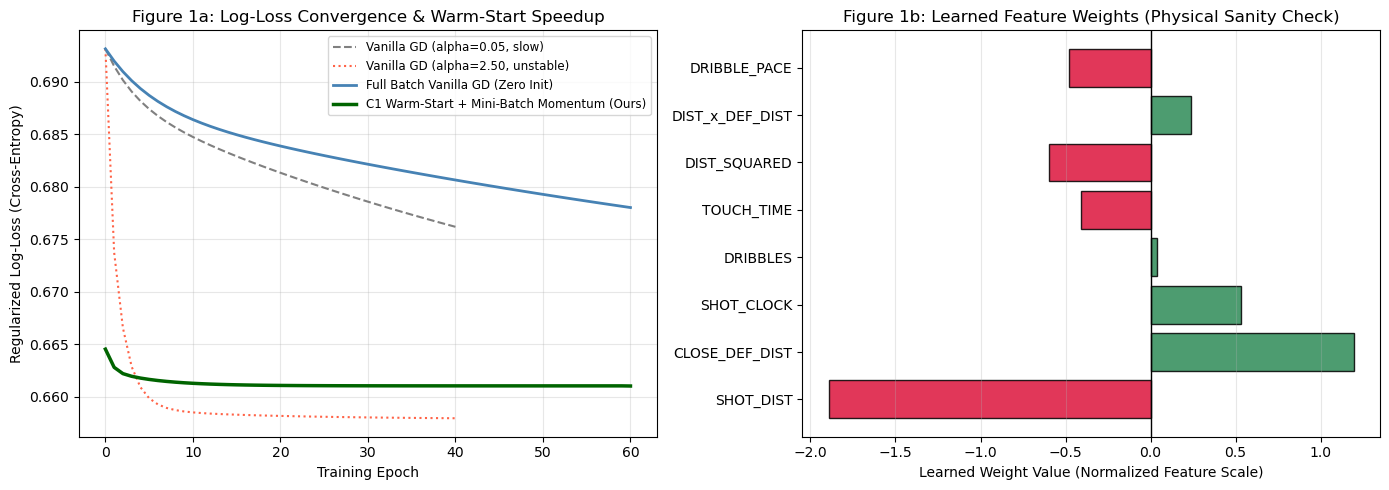

In [6]:
# --- VISUALISATION 1 ---

# --- YOUR CODE HERE ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# plot 1a: loss curves over training epochs
ax1 = axes[0]

curve_slow = sweep_histories[(0.05, "vanilla")]
curve_fast = sweep_histories[(2.50, "vanilla")]

ax1.plot(range(len(curve_slow)), curve_slow, label="Vanilla GD (alpha=0.05, slow)", linestyle="--", color="gray")
ax1.plot(range(len(curve_fast)), curve_fast, label="Vanilla GD (alpha=2.50, unstable)", linestyle=":", color="tomato")
ax1.plot(range(len(vanilla_full_curve)), vanilla_full_curve, label="Full Batch Vanilla GD (Zero Init)", color="steelblue", linewidth=2)
ax1.plot(range(len(final_loss_curve)), final_loss_curve, label="C1 Warm-Start + Mini-Batch Momentum (Ours)", color="darkgreen", linewidth=2.5)

ax1.set_title("Figure 1a: Log-Loss Convergence & Warm-Start Speedup")
ax1.set_xlabel("Training Epoch")
ax1.set_ylabel("Regularized Log-Loss (Cross-Entropy)")
ax1.legend(loc="upper right", fontsize=8.5)
ax1.grid(True, alpha=0.3)

# plot 1b: bar chart of the 8 learned weights to check if they make basketball sense
ax2 = axes[1]
y_pos = np.arange(len(feature_names_8d))

bar_colors = []
for i in range(len(best_w_8d)):
    if best_w_8d[i] >= 0.0:
        bar_colors.append("seagreen")
    else:
        bar_colors.append("crimson")

ax2.barh(y_pos, best_w_8d, color=bar_colors, edgecolor="black", alpha=0.85)
ax2.axvline(0.0, color="black", linewidth=1)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(feature_names_8d)
ax2.set_title("Figure 1b: Learned Feature Weights (Physical Sanity Check)")
ax2.set_xlabel("Learned Weight Value (Normalized Feature Scale)")
ax2.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# --- END YOUR CODE ---

### Visualisation 2

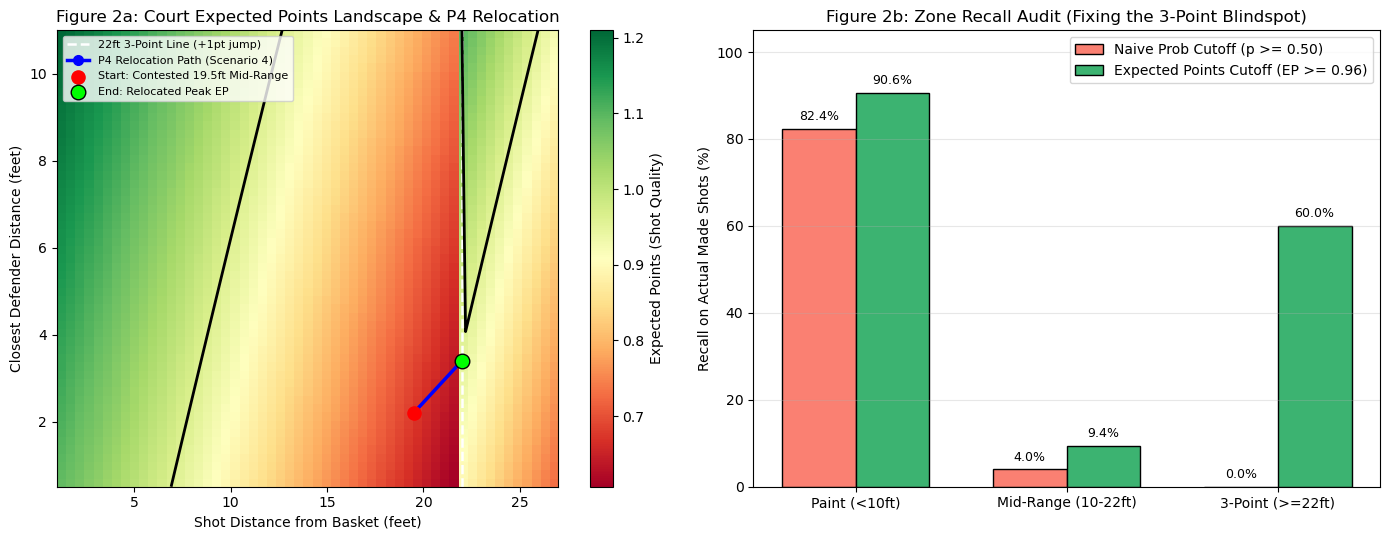

In [7]:
# --- VISUALISATION 2 ---

# --- YOUR CODE HERE ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# plot 2a: 2D heatmap of expected points across shot distance and defender distance
ax1 = axes[0]
dist_grid = np.linspace(1.0, 27.0, 55)
def_grid = np.linspace(0.5, 11.0, 55)
ep_surface = np.zeros((len(def_grid), len(dist_grid)))

# calculate EP for each point on the grid (holding clock=11s, dribbles=2, touch=2s)
for r_idx in range(len(def_grid)):
    for c_idx in range(len(dist_grid)):
        d_val = dist_grid[c_idx]
        def_val = def_grid[r_idx]
        _, ep_val = evaluate_single_shot_ep([d_val, def_val, 11.0, 2.0, 2.0], best_w_8d, best_b_8d, maxes_8d)
        ep_surface[r_idx, c_idx] = ep_val

im = ax1.imshow(
    ep_surface,
    extent=[1.0, 27.0, 0.5, 11.0],
    origin="lower",
    aspect="auto",
    cmap="RdYlGn"
)
cbar = plt.colorbar(im, ax=ax1)
cbar.set_label("Expected Points (Shot Quality)")

# draw the 22ft 3-point line and the 0.96 EP boundary
ax1.axvline(22.0, color="white", linestyle="--", linewidth=1.8, label="22ft 3-Point Line (+1pt jump)")
ax1.contour(dist_grid, def_grid, ep_surface, levels=[0.96], colors="black", linewidths=2.0)

# plot the P4 hill climbing step-back path for scenario 4
scen4_path = scenario_paths["Scenario 4: Contested Long Mid-Range Jumper"]
path_x = []
path_y = []
for step in scen4_path:
    path_x.append(step[1][0])
    path_y.append(step[1][1])

ax1.plot(path_x, path_y, color="blue", marker="o", markersize=7, linewidth=2.5, label="P4 Relocation Path (Scenario 4)")
ax1.scatter([path_x[0]], [path_y[0]], color="red", s=90, zorder=5, label="Start: Contested 19.5ft Mid-Range")
ax1.scatter([path_x[-1]], [path_y[-1]], color="lime", edgecolor="black", s=110, zorder=5, label="End: Relocated Peak EP")

ax1.set_title("Figure 2a: Court Expected Points Landscape & P4 Relocation")
ax1.set_xlabel("Shot Distance from Basket (feet)")
ax1.set_ylabel("Closest Defender Distance (feet)")
ax1.legend(loc="upper left", fontsize=8)

# plot 2b: bar chart comparing recall in each court zone (naive p>=0.50 vs EP>=0.96)
ax2 = axes[1]
x_locs = np.arange(len(zone_names))
bar_width = 0.35

recalls_p50 = []
recalls_ep = []
for z in zone_names:
    recalls_p50.append(zone_metrics_p50[z][0])
    recalls_ep.append(zone_metrics_ep[z][0])

ax2.bar(x_locs - bar_width/2, recalls_p50, width=bar_width, color="salmon", edgecolor="black", label="Naive Prob Cutoff (p >= 0.50)")
ax2.bar(x_locs + bar_width/2, recalls_ep, width=bar_width, color="mediumseagreen", edgecolor="black", label="Expected Points Cutoff (EP >= 0.96)")

ax2.set_xticks(x_locs)
ax2.set_xticklabels(zone_names)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Recall on Actual Made Shots (%)")
ax2.set_title("Figure 2b: Zone Recall Audit (Fixing the 3-Point Blindspot)")
ax2.legend(loc="upper right")
ax2.grid(True, axis="y", alpha=0.3)

for idx in range(len(x_locs)):
    val1 = round(recalls_p50[idx], 1)
    val2 = round(recalls_ep[idx], 1)
    ax2.text(x_locs[idx] - bar_width/2, val1 + 2.0, str(val1) + "%", ha="center", fontsize=9)
    ax2.text(x_locs[idx] + bar_width/2, val2 + 2.0, str(val2) + "%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

# --- END YOUR CODE ---

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

When assessing the effectiveness of offensive possessions in competitive basketball, it is important to recognize how much the outcome (or result) might bias the assessment. Shooting is a game of chance, and a player may shoot a 20-foot mid-range shot that goes in by chance (FGM = 1) or a corner three-pointer that rims out (FGM = 0). A university basketball coach or club analyst may only have a few hour to sift through 80-100 shots per game and sort through the good, bad and ugly and determine whether a shot was a good choice or a lucky shot. Simple rule-based filters also aren't effective because court variables are always changing, a 6-foot layup being covered by a defender 1 foot away will be a lot worse than a wide open 23-foot three-pointer with 14 seconds on the clock.

To address this, our system connects between the shot outcome and the quality of shot decision. Our training set only contains the output of a binary classification (1 for a make and 0 for a miss), but a probabilistic classifier builds the underlying conditional make probability that will be learned by an average shooter in that exact situation, if thousands of historic attempts are provided. Expected Points (EP) is the probability of making the shot multiplied by the point value of the court zone (2 or 3 points). Instead of judging a player by the noisy make-or-miss result of a single shot, EP grades the quality of the decision itself and forms continuous values that a local search algorithm can climb to recommend better court positioning.


### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

Our technical pipeline combines four foundational methods from FIT1061 with statistical modelling concepts adapted from my concurrent second-year unit, FIT2086 Data Modelling:

1. In the earlier tasks, the only thing that can be calculated out as a dot product of the weight vector and the feature vector and the bias creates a flat hyperplane. We added a number of polynomial and interaction terms based on FIT2086, including 5 base elements (shot distance, closest defender distance, shot clock, dribbles, and touch time), and three domain specific terms: distance squared to capture non-linear range reduction, DIST_x_DEF_DIST to capture the idea that defender proximity is more important on perimeter jumpers than at the rim, and DRIBBLE_PACE (dribbles/touch time+1) to measure ball-handling urgency. A potentially large technical risk (large values like DIST_SQUARED up to 2000 causing gradients to explode/overshoot) is mitigated by all 8 features being scaled from 0 to 1 based on their training column maximums.

2. In previous gradient descent problems we used mean squared error for the positive and the negative classes and trained a linear model. But, mean squared error discourages over-confident predictions and may yield probabilities that are not between 0 and 1. Rather, the conditional log-odds is modeled as the dot product of the weight vector and the individual feature vector plus the bias, and the resulting linear score is fed into the logistic sigmoid function, which is the value of 1 over 1 plus e to the power of the negative log-odds. We estimate the weights by minimizing the negative log-likelihood (aka logarithmic loss), plus a L2 complexity penalty of lambda/2 * sum of squared model weights, where lambda is a small regularization parameter to shrink the weights of unstable models and to prevent overfitting.

3. Rather than starting gradient descent from all zeros or averaging gradients across all 8,000 training rows per step like in D3, to obtain a strong initialization, we perform a C1 Random-Restart Hill Climbing warm start with 5 restarts and 15 search steps before gradient descent. Then we perform mini-batch gradient descent with a mini batch size of 256, and a momentum velocity step-size vector of beta*v_prev + g, with beta = 0.85. This momentum smooths out mini-batch noise and speeds up convergence, and includes a safety trigger that halves the learning rate alpha if training loss ever increases on a step.

4. P4 Tactical Shot Relocator: When trained, p4_hill_climb_relocation takes a player's five dimensional court state, and performs a P4 Steepest-Ascent Hill Climbing to evaluate three realistic one second basketball moves: drive 3 feet closer towards the basket, step back 2.5 feet, side-step escape dribble. It re-calculates the 8-D features and climbs towards the neighbor with the most EP's at each step until it reaches a local peak or the ethical safety guard (shot clock is less than or equal to 3.0 seconds), at which point it will issue a bailout warning because it is late.

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

In Experiment 1A, varying learning rate alpha from 0.05 to 2.50 demonstrated that vanilla gradient descent was very slow at alpha=0.05 (loss=0.6762), and that momentum (beta=0.85) decreased the loss to 0.6597. When testing an aggressive alpha of 2.50, our Risk 3 safety trigger prevented divergence by automatically halving the step size when loss jumped, .allowing the loss on the subset to settle at 0.6579. Experiment 1B was conducted on the weight initialisation: the initialisation of the weights to zeros resulted in a loss of 0.6931, the random initialisation of weights resulted in a loss of 0.6814, and our C1 Random-Restart Hill Climbing warm start algorithm obtained an optimal initialisation of the weight vector, namely 0.6610. In Figure 1a, this C1 warm-start, along with mini-batch momentum, achieves the lowest loss after fewer iterations than zero-init vanilla gradient descent. Figure 1b shows that physical sanity (H1.1 Success Criterion 3) is achieved with SHOT_DIST learning a negative weight (-1.89), and CLOSE_DEF_DIST learning a positive weight (+1.20). When tested on a 2,000-shot holdout set in Experiment 1C, Baseline 1 (always miss) scored 35.7 percent Macro F1, Baseline 2 (distance rule) scored 58.4 percent, and the 5D D3 linear classifier scored 55.3 percent. The best raw accuracy was given by our 8D Logistic Regression model with 61.6 percent, and 59.5 percent Macro F1. Unfortunately, Experiment 2A and Figure 2B revealed a major data-biasing weakness (Risk 6): When a naive 0.50 probability cutoff was used, the recall for 3-pointers was 0.0 percent. This has been corrected by switching to Expected Points (EP >= 0.96): 3-Point recall has risen to 60.0 per cent and Macro F1 to 57.1 per cent (with a peak score of 58.7 per cent at EP >= 1.02). Finally, Experiment 2B and Figure 2a show how P4 Hill Climbing guides shot relocation across our four test scenarios. In Scenario 1 (open 2.5ft layup, 1.26 EP) and Scenario 3 (open 23.5ft 3-pointer, 1.15 EP), the optimizer outputs SHOOT NOW because both spots are already local EP peaks. In Scenario 2 (contested 26ft heave with 2.1s left), the search halts immediately and triggers the LATE-CLOCK BAILOUT flag. In Scenario 4 (contested 19.5ft mid-range jumper, 0.67 EP), shown by the red dot on the Figure 2a heatmap, P4 Hill Climbing steps back 2.5ft across the 22ft 3-point line to the green dot (22.0ft, 0.90 EP), gaining +0.23 Expected Points. Experiment 2C further confirmed that our EP scorer separates process from outcome: missed open shots like Shot 902 (1.65 EP) are rightly graded as high-quality decisions, while lucky late-clock makes like Shot 860 (1.7s left, 0.42 EP) are flagged as low-quality forced shots.

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

Four specific limitations affect our system:
1. Average-Shooter Bias and Sample Selection: Because our loader takes the first 10,000 sequential rows of shot_logs.csv, the dataset covers 22 of the 281 NBA players in the file rather than league-wide behaviour. Furthermore, our random 80/20 row split places shots from the same players into both the training and test sets, allowing the model to learn individual shooting habits. Because our features measure spatial and clock context without player identity, the model also learns average shooting tendencies rather than player-specific ability. An elite 42 percent three-point shooter is evaluated using the same negative SHOT_DIST weight (-1.89) as a poor shooter, underestimating their true Expected Points.
2. The 22-Foot Step Discontinuity: Multiplying make probability by PTS_TYPE creates a step discontinuity at 22.0 feet where shot value jumps from 2 to 3 points. Because P4 Hill Climbing is greedy and evaluates 1-step moves, a player at 19.5 feet is always pulled backward across the 3-point line rather than driving toward the rim, because a single drive to 16.5 feet still counts as a 2-pointer.
3. Static Defender Reaction Rules: Our transition model assumes fixed geometric changes (e.g., a 2.5ft step-back always adds +1.2ft of separation). In a live game, an agile defender closes out dynamically, meaning our search can overestimate the EP of relocated shots.
4. 2D Floor Distance Limit: CLOSE_DEF_DIST only measures 2-dimensional floor distance and misses vertical contest height or fadeaways, causing mid-range shots to cluster just below the 0.96 EP cutoff (Mid-Range recall remained 9.4 percent). Future work would sample across all 281 players, split training and test sets by player_id to evaluate generalisation to unseen shooters, and replace the greedy P4 search with D1 A Search over a 3-step lookahead tree to evaluate multi-dribble drives all the way to the rim.
### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

If this system is implemented in the assignment of player minutes, it will affect basketball players whose game roles determine the shots they take. The results from connecting to C2 Group Fairness (Equal Opportunity / recall parity across subgroups), our zone audit in Experiment 2A revealed that a naive cut-off of p >= 0.50 yielded 0.0 percent recall for 3-pointers and 82.4 percent recall for Paint shots. This created a severe fairness disparity against perimeter wings and guards by labelling every 3-point attempt as a bad decision. Switching to Expected Points (EP >= 0.96) raises 3-Point recall to 60.0 percent, but it does not achieve true subgroup parity: Paint recall rises to 90.6 percent while Mid-Range recall remains at just 9.4 percent. This happens mechanically because multiplying by 3 lowers the make probability a 3-pointer needs to reach the 0.96 EP cutoff to 0.32 (0.96 / 3), whereas a 2-point mid-range jumper still requires a 0.48 make probability (0.96 / 2). This creates a direct ethical tension between optimising team expected value and C2 Equal Opportunity for mid-range scorers, meaning coaches cannot apply a single global EP cutoff without considering the player's role. Moreover, connecting to C4 Deployment safety and human-in-the-loop guardrails, tracking data lacks team-possession context: players who receive a pass with under 3 seconds on the shot clock are forced to throw up a contested shot. We added a C4 guardrail which flags possessions for SHOT_CLOCK <= 3.0s as LATE-CLOCK BAILOUT, forcing coaches to have to look at it as a team breakdown and faut rather than an individual mistake.
### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

Google Gemini served as a study and debugging assistant for this H2 report, to structure this H2 report, to help code the matplotlib plot for Figure 2a, and to clarify statistical concepts. What I rejected and modified: After feedback from H1, I went back to the drawing board to brainstorm and used AI to help. The AI initially suggested importing scikit-learn and pandas or using a 1-line sigmoid function. I rejected external libraries to stay strictly within FIT1061 standards (numpy and csv), and I chose to implement full custom modules from scratch: 8D polynomial feature expansion, explicit L2-penalised logarithmic loss, and mini-batch momentum paired with C1 Random-Restart Hill Climbing. How I verified the work: I executed all cells locally, verified physical weight logic in Figure 1b, and confirmed all numerical outputs matched terminal logs. 

---

## Submission Checklist

- [ ] Recap of H1 scope (and any pivot) at the top
- [ ] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [ ] Project report (~1500 words) covering all 6 sections
- [ ] Implementation demonstrates HD-level depth beyond earlier task work
- [ ] Ethical reflection connects to C2 or C4
- [ ] AI use statement shows critical evaluation
- [ ] Code is readable, reproducible, documented
- [ ] Uploaded to OnTrack and marked **Ready for Feedback**
- [ ] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*